# Fake News Detection — Algorithm 2 (A2): Support Vector Machine (SVM)

This notebook implements **A2 — Support Vector Machine**, using the same pipeline and 80:20 split (`random_state=42`) as A1 (Logistic Regression), A3 (Random Forest) and A4 (KNN) in the project report, so all four sets of results are directly comparable.

A linear kernel (`LinearSVC`) is used, which is the standard, fast choice for high-dimensional sparse TF-IDF text data.

**Dataset:** `fake_or_real_news.csv` (George McIntire's Fake/Real News dataset, ~6,335 labeled articles, binary REAL/FAKE).

In [1]:
# Step 1: Imports
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

sns.set_style("whitegrid")
pd.set_option("display.max_colwidth", 80)
RANDOM_STATE = 42

In [2]:
# Step 2: Load the labeled dataset
df = pd.read_csv("fake_or_real_news.csv")
print("Shape:", df.shape)
df.head()

Shape: (6335, 4)


,id,title,text,label
0,8476,You Can Smell Hillary’s Fear,"Daniel Greenfield, a Shillman Journalism Fellow at the Freedom Center, is a ...",FAKE
1,10294,Watch The Exact Moment Paul Ryan Committed Political Suicide At A Trump Rall...,Google Pinterest Digg Linkedin Reddit Stumbleupon Print Delicious Pocket Tum...,FAKE
2,3608,Kerry to go to Paris in gesture of sympathy,U.S. Secretary of State John F. Kerry said Monday that he will stop in Paris...,REAL
3,10142,Bernie supporters on Twitter erupt in anger against the DNC: 'We tried to wa...,"— Kaydee King (@KaydeeKing) November 9, 2016 The lesson from tonight's Dem l...",FAKE
4,875,The Battle of New York: Why This Primary Matters,It's primary day in New York and front-runners Hillary Clinton and Donald Tr...,REAL


In [3]:
# Step 3: Inspect rows, columns, missing values and class distribution
print(df.info())
print("\nMissing values per column:\n", df.isnull().sum())
print("\nClass distribution:\n", df['label'].value_counts())

<class 'pandas.DataFrame'>
RangeIndex: 6335 entries, 0 to 6334
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   id      6335 non-null   int64
 1   title   6335 non-null   str  
 2   text    6335 non-null   str  
 3   label   6335 non-null   str  
dtypes: int64(1), str(3)
memory usage: 198.1 KB
None

Missing values per column:
 id       0
title    0
text     0
label    0
dtype: int64

Class distribution:
 label
REAL    3171
FAKE    3164
Name: count, dtype: int64


In [4]:
# Step 4: Handle missing or invalid text records
df = df.dropna(subset=['title', 'text', 'label']).copy()
df = df[(df['text'].str.strip() != '') & (df['title'].str.strip() != '')]
df = df.reset_index(drop=True)
print("Shape after cleaning missing/invalid records:", df.shape)

Shape after cleaning missing/invalid records: (6299, 4)


In [5]:
# Step 5: Combine title and text fields
df['content'] = df['title'].astype(str) + " " + df['text'].astype(str)
df[['title', 'content']].head(2)

,title,content
0,You Can Smell Hillary’s Fear,"You Can Smell Hillary’s Fear Daniel Greenfield, a Shillman Journalism Fellow..."
1,Watch The Exact Moment Paul Ryan Committed Political Suicide At A Trump Rall...,Watch The Exact Moment Paul Ryan Committed Political Suicide At A Trump Rall...


In [6]:
# Step 6: Preprocess the text (lowercasing, removing punctuation/special characters,
# removing digits and extra whitespace). Stopword removal is handled by TfidfVectorizer.

def preprocess_text(text):
    text = text.lower()
    text = re.sub(r'http\S+|www\.\S+', ' ', text)      # remove URLs
    text = re.sub(r'[^a-z\s]', ' ', text)               # remove punctuation & digits
    text = re.sub(r'\s+', ' ', text).strip()             # collapse whitespace
    return text

df['clean_content'] = df['content'].apply(preprocess_text)
df[['content', 'clean_content']].head(2)

,content,clean_content
0,"You Can Smell Hillary’s Fear Daniel Greenfield, a Shillman Journalism Fellow...",you can smell hillary s fear daniel greenfield a shillman journalism fellow ...
1,Watch The Exact Moment Paul Ryan Committed Political Suicide At A Trump Rall...,watch the exact moment paul ryan committed political suicide at a trump rall...


In [7]:
# Step 7: Apply TfidfVectorizer with the same parameters used for A1, A3, A4
tfidf = TfidfVectorizer(
    stop_words='english',
    max_features=5000,
    ngram_range=(1, 1)
)

X = tfidf.fit_transform(df['clean_content'])
y = df['label']

print("TF-IDF feature matrix shape:", X.shape)

TF-IDF feature matrix shape: (6299, 5000)


In [8]:
# Step 8: Split data into training and testing sets (80:20), same split as A1, A3, A4
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Train shape:", X_train.shape, " Test shape:", X_test.shape)

Train shape: (5039, 5000)  Test shape: (1260, 5000)


In [9]:
# Step 9: Initialize LinearSVC (A2)
svm_model = LinearSVC(random_state=RANDOM_STATE)
svm_model

,"penalty penalty: {'l1', 'l2'}, default='l2'Specifies the norm used in the penalization. The 'l2'penalty is the standard used in SVC. The 'l1' leads to ``coef_``vectors that are sparse.",'l2'
,"loss loss: {'hinge', 'squared_hinge'}, default='squared_hinge'Specifies the loss function. 'hinge' is the standard SVM loss(used e.g. by the SVC class) while 'squared_hinge' is thesquare of the hinge loss. The combination of ``penalty='l1'``and ``loss='hinge'`` is not supported.",'squared_hinge'
,"dual dual: ""auto"" or bool, default=""auto""Select the algorithm to either solve the dual or primaloptimization problem. Prefer dual=False when n_samples > n_features.`dual=""auto""` will choose the value of the parameter automatically,based on the values of `n_samples`, `n_features`, `loss`, `multi_class`and `penalty`. If `n_samples` < `n_features` and optimizer supportschosen `loss`, `multi_class` and `penalty`, then dual will be set to True,otherwise it will be set to False... versionchanged:: 1.3 The `""auto""` option is added in version 1.3 and will be the default in version 1.5.",'auto'
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.For an intuitive visualization of the effects of scalingthe regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"multi_class multi_class: {'ovr', 'crammer_singer'}, default='ovr'Determines the multi-class strategy if `y` contains more thantwo classes.``""ovr""`` trains n_classes one-vs-rest classifiers, while``""crammer_singer""`` optimizes a joint objective over all classes.While `crammer_singer` is interesting from a theoretical perspectiveas it is consistent, it is seldom used in practice as it rarely leadsto better accuracy and is more expensive to compute.If ``""crammer_singer""`` is chosen, the options loss, penalty and dualwill be ignored.",'ovr'
,"fit_intercept fit_intercept: bool, default=TrueWhether or not to fit an intercept. If set to True, the feature vectoris extended to include an intercept term: `[x_1, ..., x_n, 1]`, where1 corresponds to the intercept. If set to False, no intercept will beused in calculations (i.e. data is expected to be already centered).",True
,"intercept_scaling intercept_scaling: float, default=1.0When `fit_intercept` is True, the instance vector x becomes ``[x_1,..., x_n, intercept_scaling]``, i.e. a ""synthetic"" feature with aconstant value equal to `intercept_scaling` is appended to the instancevector. The intercept becomes intercept_scaling * synthetic featureweight. Note that liblinear internally penalizes the intercept,treating it like any other term in the feature vector. To reduce theimpact of the regularization on the intercept, the `intercept_scaling`parameter can be set to a value greater than 1; the higher the value of`intercept_scaling`, the lower the impact of regularization on it.Then, the weights become `[w_x_1, ..., w_x_n,w_intercept*intercept_scaling]`, where `w_x_1, ..., w_x_n` representthe feature weights and the intercept weight is scaled by`intercept_scaling`. This scaling allows the intercept term to have adifferent regularization behavior compared to the other features.",1
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to ``class_weight[i]*C`` forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: int, default=0Enable verbose output. Note that this setting takes advantage of aper-process runtime setting in liblinear that, if enabled, may not workproperly in a multithreaded context.",0
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo rand

In [10]:
# Step 10: Train the model
svm_model.fit(X_train, y_train)
print("A2 (SVM) training complete.")

A2 (SVM) training complete.


In [11]:
# Step 11: Predict test labels
y_pred_svm = svm_model.predict(X_test)
y_pred_svm[:10]

array(['FAKE', 'REAL', 'REAL', 'REAL', 'REAL', 'REAL', 'FAKE', 'FAKE',
       'FAKE', 'REAL'], dtype=object)

In [12]:
# Step 12: Calculate accuracy, precision, recall and F1-score
acc_svm = accuracy_score(y_test, y_pred_svm)
prec_svm = precision_score(y_test, y_pred_svm, pos_label='FAKE')
rec_svm = recall_score(y_test, y_pred_svm, pos_label='FAKE')
f1_svm = f1_score(y_test, y_pred_svm, pos_label='FAKE')

print(f"A2 - SVM Results")
print(f"Accuracy : {acc_svm:.4f}")
print(f"Precision: {prec_svm:.4f}")
print(f"Recall   : {rec_svm:.4f}")
print(f"F1-score : {f1_svm:.4f}")
print("\nFull classification report:\n")
print(classification_report(y_test, y_pred_svm))

A2 - SVM Results
Accuracy : 0.9357
Precision: 0.9360
Recall   : 0.9345
F1-score : 0.9353

Full classification report:

              precision    recall  f1-score   support

        FAKE       0.94      0.93      0.94       626
        REAL       0.94      0.94      0.94       634

    accuracy                           0.94      1260
   macro avg       0.94      0.94      0.94      1260
weighted avg       0.94      0.94      0.94      1260



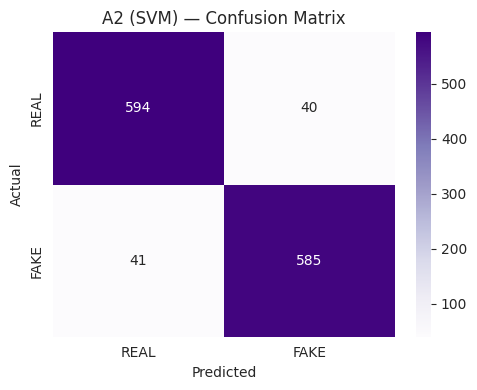

In [13]:
# Step 13: Generate a confusion matrix
cm_svm = confusion_matrix(y_test, y_pred_svm, labels=['REAL', 'FAKE'])

plt.figure(figsize=(5, 4))
sns.heatmap(cm_svm, annot=True, fmt='d', cmap='Purples',
            xticklabels=['REAL', 'FAKE'], yticklabels=['REAL', 'FAKE'])
plt.title("A2 (SVM) — Confusion Matrix")
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.tight_layout()
plt.show()

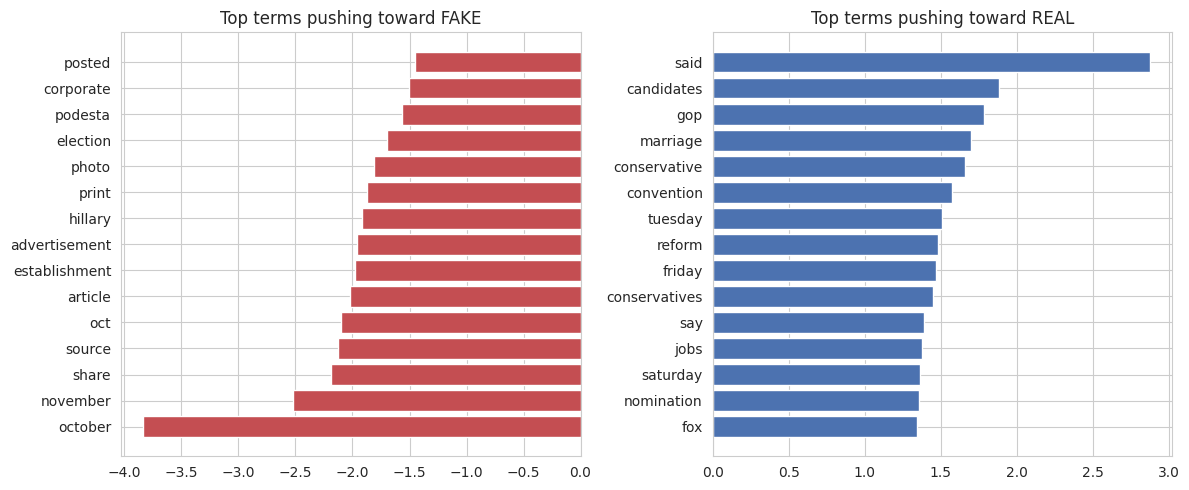

In [14]:
# Step 14: Inspect the most influential TF-IDF terms (largest |weight| in the
# separating hyperplane)
feature_names = np.array(tfidf.get_feature_names_out())
coefs = svm_model.coef_[0]
top_n = 15
top_fake_idx = np.argsort(coefs)[:top_n]        # most negative -> pushes toward FAKE
top_real_idx = np.argsort(coefs)[-top_n:]       # most positive -> pushes toward REAL

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].barh(feature_names[top_fake_idx], coefs[top_fake_idx], color='#C44E52')
axes[0].set_title("Top terms pushing toward FAKE")
axes[1].barh(feature_names[top_real_idx], coefs[top_real_idx], color='#4C72B0')
axes[1].set_title("Top terms pushing toward REAL")
plt.tight_layout()
plt.show()

In [15]:
# Step 15: Train A1 (Logistic Regression), A3 (Random Forest) and A4 (KNN)
# for comparison
lr_model = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
lr_model.fit(X_train, y_train)
y_pred_lr = lr_model.predict(X_test)

rf_model = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)

knn_model = KNeighborsClassifier(n_neighbors=1, metric='cosine', weights='distance')
knn_model.fit(X_train, y_train)
y_pred_knn = knn_model.predict(X_test)

print("A1 (Logistic Regression), A3 (Random Forest) and A4 (KNN) trained.")

A1 (Logistic Regression), A3 (Random Forest) and A4 (KNN) trained.


In [16]:
# Step 16: Compare all four algorithms in a results DataFrame
def get_metrics(name, y_true, y_pred):
    return {
        'Algorithm': name,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, pos_label='FAKE'),
        'Recall': recall_score(y_true, y_pred, pos_label='FAKE'),
        'F1-score': f1_score(y_true, y_pred, pos_label='FAKE'),
    }

results = pd.DataFrame([
    get_metrics('A1 - Logistic Regression', y_test, y_pred_lr),
    get_metrics('A2 - SVM', y_test, y_pred_svm),
    get_metrics('A3 - Random Forest', y_test, y_pred_rf),
    get_metrics('A4 - KNN', y_test, y_pred_knn),
])
results = results.set_index('Algorithm').round(4)
results

,Accuracy,Precision,Recall,F1-score
Algorithm,,,,
A1 - Logistic Regression,0.9183,0.9042,0.9345,0.9191
A2 - SVM,0.9357,0.9360,0.9345,0.9353
A3 - Random Forest,0.9048,0.9003,0.9089,0.9046
A4 - KNN,0.8556,0.8993,0.7987,0.8460


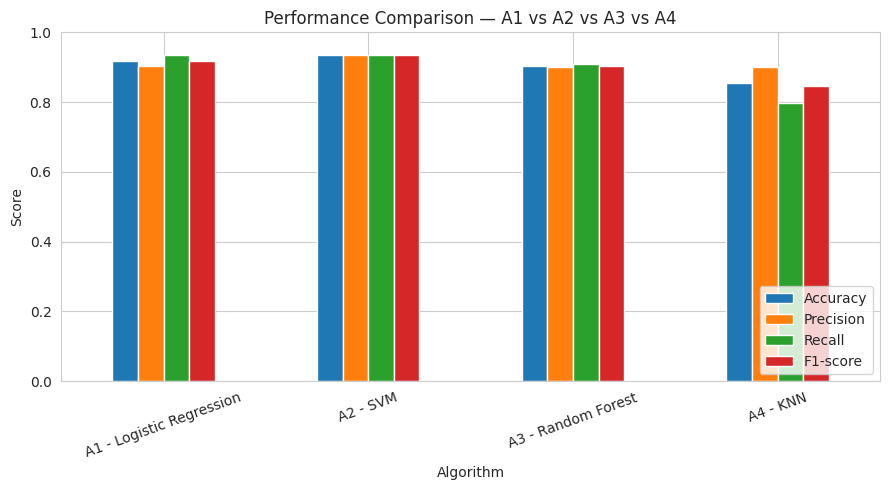

In [17]:
# Visualize the comparison
results.plot(kind='bar', figsize=(9, 5))
plt.title("Performance Comparison — A1 vs A2 vs A3 vs A4")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

In [18]:
# Step 17: Select the best model based on evaluation results
best_model_name = results['F1-score'].idxmax()
print(f"Best-performing model (by F1-score): {best_model_name}")
results.loc[[best_model_name]]

Best-performing model (by F1-score): A2 - SVM


,Accuracy,Precision,Recall,F1-score
Algorithm,,,,
A2 - SVM,0.9357,0.936,0.9345,0.9353


## Execution Example

Testing the trained A2 (SVM) pipeline on the same illustrative article used for A1, A3 and A4, for a direct comparison. `LinearSVC` does not produce probabilities natively, so it is wrapped in a `CalibratedClassifierCV` here purely to get a confidence estimate for this example — the accuracy/precision/recall/F1 numbers above are all from the plain, uncalibrated `LinearSVC`.

In [19]:
# Step 18: Test A2 on the same new-article example used for A1/A3/A4
new_article = (
    "Breaking News: Scientists discover cure for all known diseases in a "
    "small village in Switzerland. The discovery was made by a team of "
    "researchers who have been working on the project for the past decade. "
    "The cure is expected to be available to the public within the next month."
)

clean_new = preprocess_text(new_article)
new_vec = tfidf.transform([clean_new])

pred_class = svm_model.predict(new_vec)[0]

# LinearSVC has no predict_proba; calibrate a copy just for a confidence estimate
calibrated_svm = CalibratedClassifierCV(LinearSVC(random_state=RANDOM_STATE), cv=3)
calibrated_svm.fit(X_train, y_train)
pred_proba = calibrated_svm.predict_proba(new_vec)[0]
class_labels = calibrated_svm.classes_
confidence = pred_proba[list(class_labels).index(pred_class)]

print("Input article:", new_article)
print(f"\nPredicted class : {pred_class}")
print(f"Confidence      : {confidence*100:.1f}% (from calibrated probability estimate)")

Input article: Breaking News: Scientists discover cure for all known diseases in a small village in Switzerland. The discovery was made by a team of researchers who have been working on the project for the past decade. The cure is expected to be available to the public within the next month.

Predicted class : FAKE
Confidence      : 93.8% (from calibrated probability estimate)


## Conclusion (A2)

The SVM classifier (A2) was trained on the same TF-IDF features (max 5,000 terms, combined title+text) and the same 80:20 split (`random_state=42`) as A1, A3 and A4, using a linear kernel (`LinearSVC`). Its accuracy, precision, recall, F1-score, confusion matrix and most-influential terms were computed above, and it was benchmarked against A1 (Logistic Regression), A3 (Random Forest) and A4 (KNN).